# Electron TOF → kinetic energy calibration from argon

Assign argon lines to peaks of the electron TOF spectrum and fit

$$t = t_0 + \frac{a}{\sqrt{E_\mathrm{kin} - E_0}}, \qquad E_\mathrm{kin}(t) = \left(\frac{a}{t - t_0}\right)^2 + E_0$$

by least squares. $t_0$ is the time offset, $a = L\sqrt{m_e/2e}$ gives the effective flight length
($L = a / 1686.5$ m for $a$ in ns·√eV) and $E_0$ the energy offset of the spectrometer potentials (retardation:
the electrons drift with $E_\mathrm{kin} - E_0$).

**Data.** Run 60538 (`Argon_2807259185`), all 100 pulses. Photon energy: the nominal (undulator set wavelength)
value of the run, 275.52 eV. Same spectrometer as the glycine beamtime.

**Lines** follow D. Schwickert, PhD thesis (Hamburg 2022), p. 48
([ediss.sub.uni-hamburg.de/handle/ediss/9628](https://ediss.sub.uni-hamburg.de/handle/ediss/9628)): photolines
at $E_\mathrm{kin} = h
u - E_B$ with $E_B$ from its Table 4, Auger energies at the local peaks of the summed
(σ = 2.5 % $E_\mathrm{kin}$) Ar L₂,₃MM line spectrum of its Fig. 35b (lines from its ref. [103], measured at 265 eV).

| line | eV | |
|---|---|---|
| Ar 2p₃/₂, 2p₁/₂ (L₃, L₂) | $E_B$ = 248.4, 250.6 | strongest photolines here, slow (~25 eV) |
| Ar 3s (M₁) | $E_B$ = 29.3 | |
| Ar 3p (M₂,₃) | $E_B$ = 15.7 / 15.9, unresolved: 15.77 | the fastest electrons |
| L₂,₃–M₂,₃M₂,₃ | 204.7 | peak of the multiplet (201.2–207.5) |
| L₂,₃–M₁M₂,₃ | 190.2 | shoulder, no peak of its own: intensity-weighted centre of its lines 187.5–193.2 |
| L₂,₃–M₁M₁ (measured) | 179.1 | peak of the 170–182 eV group |
| L₂,₃–M₁M₁ (calculated) | 147.1 | weak, flat-topped |

The fast lines (90–115 ns) alone span too small a range of $1/\sqrt{E}$ to separate $t_0$ from $E_0$; the slow 2p
photolines fix that (the thesis fit uses them too).

`ASSIGNMENTS` pairs a TOF with a line and the uncertainty of that TOF, which weights the fit. The TOFs are the
maxima of the spectrum (0.1 ns bins, smoothed with σ = 0.2 ns; 2p: 0.5 ns, σ = 0.75 ns) or, for shoulders, the
minima of its second derivative: maxima ±0.3–0.5 ns, shoulders and weak features ±0.5–1 ns.

In [1]:
# ---- Parameters ---------------------------------------------------------------
COMBINED_H5 = "run60538_Argon_2807259185.h5"   # relative to config.COMBINED_DIR or absolute
RUN = 60538                  # raw files of this run give the nominal photon energy
PHOTON_ENERGY = None         # eV; None = nominal value of RUN
BUNCH_RANGE = (0, 100)
TOF_RANGE = (50, 1000)       # ns
TOF_BIN = 0.2                # ns

# Reference lines: name -> ("photo", binding energy) or ("auger", kinetic energy), in eV
LINES = {
    "Ar 3p":              ("photo", 15.77),   # 3p3/2 15.7, 3p1/2 15.9 (2:1), unresolved
    "Ar 3s":              ("photo", 29.3),
    "Ar 2p3/2":           ("photo", 248.4),
    "Ar 2p1/2":           ("photo", 250.6),
    "L2,3-M2,3M2,3":      ("auger", 204.7),
    "L2,3-M1M2,3":        ("auger", 190.2),
    "L2,3-M1M1 (exp.)":   ("auger", 179.1),
    "L2,3-M1M1 (calc.)":  ("auger", 147.1),
}

# (TOF in ns, line, uncertainty of the TOF reading in ns)
ASSIGNMENTS = [
    (90.35,  "Ar 3p",             0.3),   # maximum
    (93.65,  "Ar 3s",             0.5),   # small maximum on the 3p tail; fits ~6 eV low (3p-1 satellites?) - try without
    (100.15, "L2,3-M2,3M2,3",     0.3),   # maximum
    (103.05, "L2,3-M1M2,3",       0.5),   # shoulder
    (106.35, "L2,3-M1M1 (exp.)",  0.3),   # maximum
    (114.25, "L2,3-M1M1 (calc.)", 1.0),   # very weak shoulder
    (247.25, "Ar 2p3/2",          0.5),   # maximum
    (256.75, "Ar 2p1/2",          1.0),   # shoulder on the 2p3/2 tail
]
P0 = (10.0, 1300.0, 0.0)     # start values: t0 (ns), a (ns sqrt(eV)), E0 (eV)
ZOOMS = [(85, 120), (225, 275)]   # ns windows shown with the assignments

In [2]:
# ---- Imports and paths ------------------------------------------------------
from pathlib import Path
import glob
import sys

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "analysis" / "scripts" / "config.py").exists())
sys.path.insert(0, str(REPO_ROOT / "analysis" / "scripts"))
import config
import data_loading

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
TDC_PER_NS = 10
NS_SQRT_EV_PER_M = 1686.5    # sqrt(m_e / 2e) in ns sqrt(eV) per metre

## Spectrum

In [3]:
h5_path = Path(COMBINED_H5)
h5_path = h5_path if h5_path.is_absolute() else config.COMBINED_DIR / h5_path
data = data_loading.load_data(str(h5_path), config=1, load_vls=False)
hits = data.tofs_e[:, slice(*BUNCH_RANGE)]
t_hits = hits[hits > 0].astype(np.float64) / TDC_PER_NS
n_shots = int(np.isfinite(data.gmd[:, slice(*BUNCH_RANGE)]).sum())

edges = np.arange(TOF_RANGE[0], TOF_RANGE[1] + TOF_BIN, TOF_BIN)
tof = 0.5 * (edges[1:] + edges[:-1])
spec = np.histogram(t_hits, edges)[0] / n_shots          # hits per shot per bin

if PHOTON_ENERGY is None:
    raw = sorted(glob.glob(str(config.RAW_H5_DIR / f"*run{RUN}_*.h5")))
    PHOTON_ENERGY = float(np.nanmedian(data_loading.read_nominal_energy(raw, data.tID)[0]))
line_ke = {k: (PHOTON_ENERGY - v if kind == "photo" else v) for k, (kind, v) in LINES.items()}
print(f"{h5_path.name}: {n_shots} shots, {t_hits.size} electron hits; photon energy {PHOTON_ENERGY:.2f} eV")
for k, ke in line_ke.items():
    print(f"  {k:14s} {ke:7.2f} eV")

run60538_Argon_2807259185.h5: 605300 shots, 2903529 electron hits; photon energy 275.52 eV
  Ar 3p           259.75 eV
  Ar 3s           246.22 eV
  Ar 2p3/2         27.12 eV
  Ar 2p1/2         24.92 eV
  L2,3-M2,3M2,3   204.70 eV
  L2,3-M1M2,3     190.20 eV
  L2,3-M1M1 (exp.)  179.10 eV
  L2,3-M1M1 (calc.)  147.10 eV


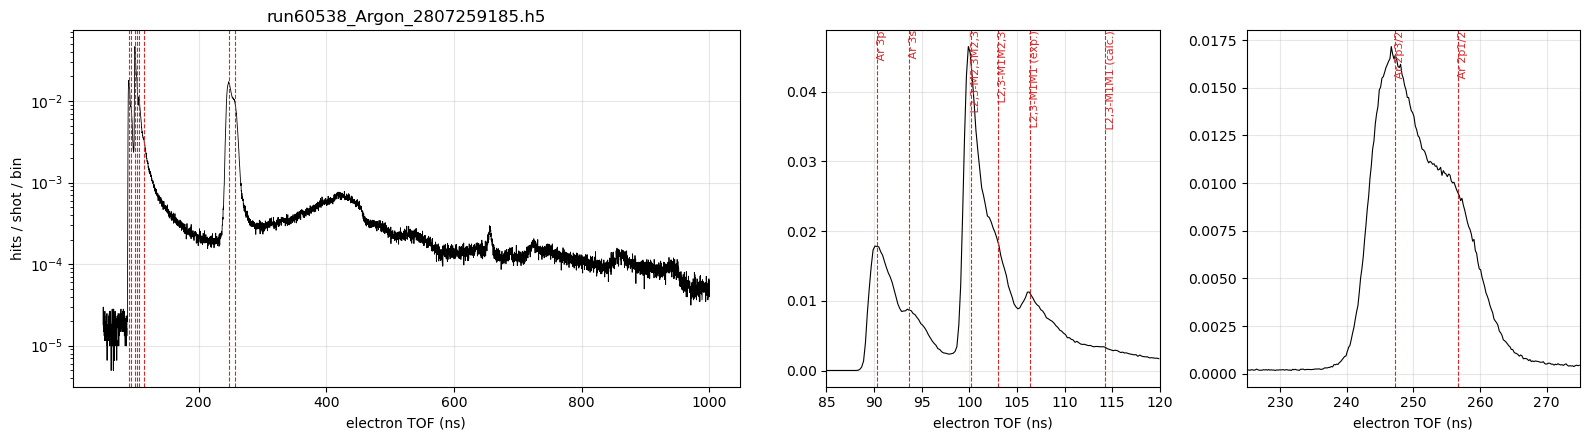

In [4]:
fig, axs = plt.subplots(1, 1 + len(ZOOMS), figsize=(16, 4.5), gridspec_kw={"width_ratios": [2] + [1] * len(ZOOMS)})
axs[0].semilogy(tof, spec, lw=0.6, color="k")
axs[0].set(xlabel="electron TOF (ns)", ylabel="hits / shot / bin", title=h5_path.name)
for ax, (lo, hi) in zip(axs[1:], ZOOMS):
    m = (tof >= lo) & (tof <= hi)
    ax.plot(tof[m], spec[m], lw=0.8, color="k")
    ax.set(xlim=(lo, hi), xlabel="electron TOF (ns)")
for t_a, name, _ in ASSIGNMENTS:
    for ax in axs:
        ax.axvline(t_a, color="C3", lw=0.8, ls="--")
    for ax, (lo, hi) in zip(axs[1:], ZOOMS):
        if lo <= t_a <= hi:
            ax.text(t_a, ax.get_ylim()[1], f" {name}", rotation=90, va="top", fontsize=8, color="C3")
fig.tight_layout()
plt.show()

## Least-squares fit

In [5]:
t_pts = np.array([t for t, _, _ in ASSIGNMENTS])
ke_pts = np.array([line_ke[name] for _, name, _ in ASSIGNMENTS])
sig_pts = np.array([s for _, _, s in ASSIGNMENTS])
names = [name for _, name, _ in ASSIGNMENTS]


def tof_of_ke(ke, t0, a, E0):
    return t0 + a / np.sqrt(ke - E0)


def ke_of_tof(t, t0, a, E0):
    t = np.asarray(t, dtype=float)
    return np.where(t > t0, (a / (t - t0)) ** 2 + E0, np.nan)


popt, pcov = curve_fit(tof_of_ke, ke_pts, t_pts, p0=P0, sigma=sig_pts, absolute_sigma=True, maxfev=20000)
perr = np.sqrt(np.diag(pcov))
t0, a, E0 = popt
resid = t_pts - tof_of_ke(ke_pts, *popt)
chi2, dof = np.sum((resid / sig_pts) ** 2), len(t_pts) - 3

print(f"t0 = {t0:.2f} ± {perr[0]:.2f} ns")
print(f"a  = {a:.1f} ± {perr[1]:.1f} ns sqrt(eV)   (L = {a / NS_SQRT_EV_PER_M:.3f} ± {perr[1] / NS_SQRT_EV_PER_M:.3f} m)")
print(f"E0 = {E0:.2f} ± {perr[2]:.2f} eV")
print(f"chi2 = {chi2:.2f} for {dof} degrees of freedom")
print(f"{'line':14s} {'TOF':>7s} {'KE':>8s} {'TOF - fit':>10s} {'KE(TOF) - KE':>13s}")
for n, t, ke, r in zip(names, t_pts, ke_pts, resid):
    print(f"{n:14s} {t:7.2f} {ke:8.2f} {r:+9.2f}  {ke_of_tof(t, *popt) - ke:+12.2f}")

t0 = 14.75 ± 2.33 ns
a  = 1224.7 ± 37.0 ns sqrt(eV)   (L = 0.726 ± 0.022 m)
E0 = -0.64 ± 1.11 eV
chi2 = 7.49 for 5 degrees of freedom
line               TOF       KE  TOF - fit  KE(TOF) - KE
Ar 3p            90.35   259.75     -0.29         +2.03
Ar 3s            93.65   246.22     +0.95         -5.93
L2,3-M2,3M2,3   100.15   204.70     -0.06         +0.31
L2,3-M1M2,3     103.05   190.20     -0.35         +1.52
L2,3-M1M1 (exp.)  106.35   179.10     +0.25         -0.99
L2,3-M1M1 (calc.)  114.25   147.10     -1.26         +3.76
Ar 2p3/2        247.25    27.12     +0.07         -0.02
Ar 2p1/2        256.75    24.92     -0.23         +0.05


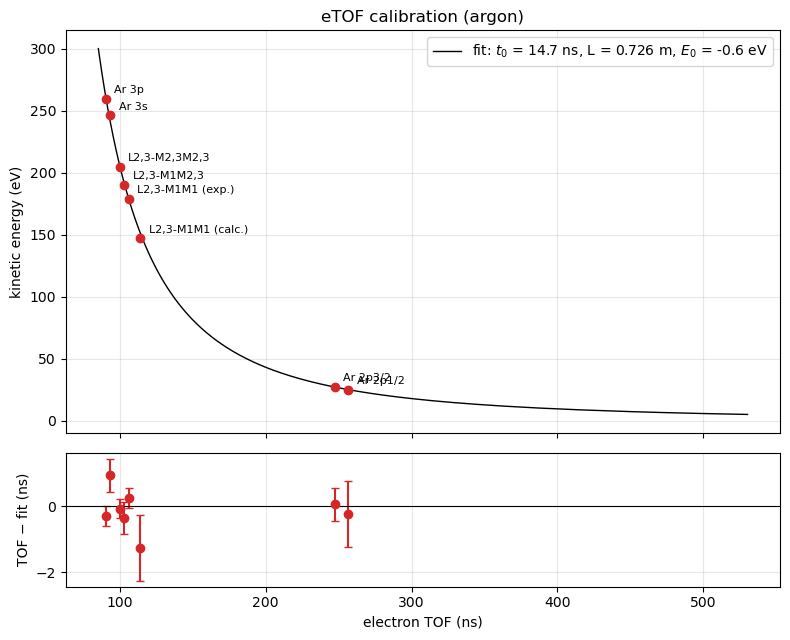

In [6]:
fig, (ax, axr) = plt.subplots(2, 1, figsize=(8, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
kk = np.linspace(max(E0 + 2, 5), 300, 400)
ax.plot(tof_of_ke(kk, *popt), kk, "k-", lw=1,
        label=f"fit: $t_0$ = {t0:.1f} ns, L = {a / NS_SQRT_EV_PER_M:.3f} m, $E_0$ = {E0:.1f} eV")
ax.errorbar(t_pts, ke_pts, xerr=sig_pts, fmt="o", color="C3", capsize=3)
for n, t, ke in zip(names, t_pts, ke_pts):
    ax.annotate(n, (t, ke), xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.set(ylabel="kinetic energy (eV)", title="eTOF calibration (argon)")
ax.legend()
axr.errorbar(t_pts, resid, yerr=sig_pts, fmt="o", color="C3", capsize=3)
axr.axhline(0, color="k", lw=0.8)
axr.set(xlabel="electron TOF (ns)", ylabel="TOF − fit (ns)")
fig.tight_layout()
plt.show()

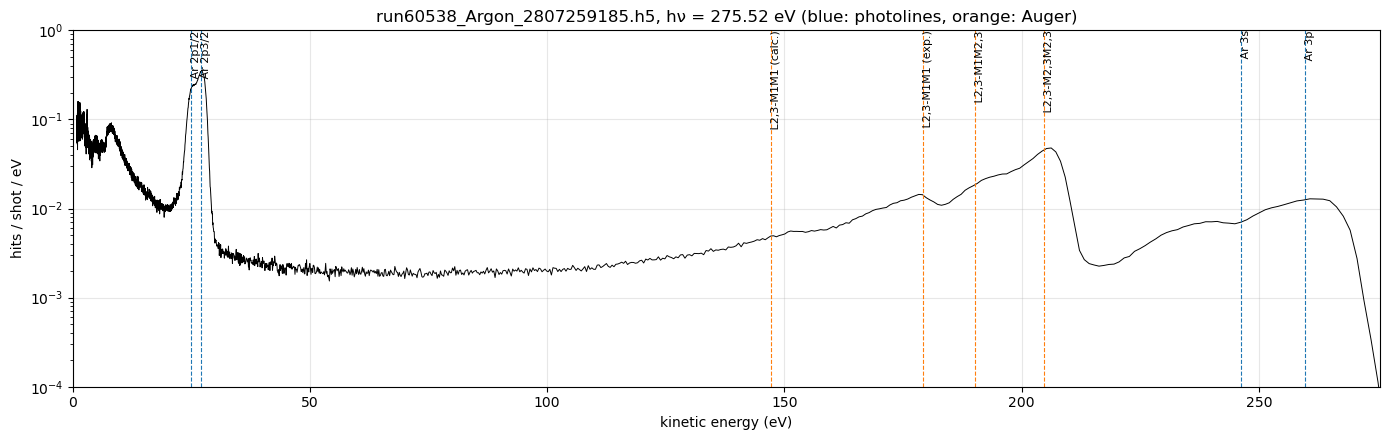

In [9]:
# Spectrum on the calibrated energy axis (per eV), with the reference lines
ke_edges = ke_of_tof(edges, *popt)
ok = np.isfinite(ke_edges[:-1]) & np.isfinite(ke_edges[1:])
per_ev = np.where(ok, spec / np.abs(np.diff(ke_edges)), np.nan)
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.semilogy(ke_of_tof(tof, *popt), per_ev, lw=0.7, color="k")
for k, ke in line_ke.items():
    ax.axvline(ke, color="C0" if LINES[k][0] == "photo" else "C1", lw=0.8, ls="--")
    ax.text(ke, 1, f" {k}", rotation=90, va="top", fontsize=8, transform=ax.get_xaxis_transform())
ax.set(xlim=(0, PHOTON_ENERGY), xlabel="kinetic energy (eV)", ylabel="hits / shot / eV",
       title=f"{h5_path.name}, hν = {PHOTON_ENERGY:.2f} eV (blue: photolines, orange: Auger)")
ax.set_ylim(1e-4, 1e0)

# ax.axvline(150) # L2,3-M1M1
# ax.axvline(177) # L2,3-M1M1
# ax.axvline(190) # L2,3-M1M2,3
# ax.axvline(204) # L2,3-M2,3M2,3
# ax.axvline(233) # M1 3s
# ax.axvline(258) # M2 3p1/2, M2 3p3/2
fig.tight_layout()
plt.show()

In [8]:
print(tof_of_ke(150, *popt), ' -> L2,3-M1M1')
print(tof_of_ke(177, *popt), ' -> L2,3-M1M1')
print(tof_of_ke(190, *popt), ' -> L2,3-M1M2,3')
print(tof_of_ke(204, *popt), ' -> L2,3-M2,3M2,3')
print(tof_of_ke(233, *popt), ' -> M1 3s')
print(tof_of_ke(258, *popt), ' -> M2 3p1/2, M2 3p3/2')

114.53225014841603  -> L2,3-M1M1
106.63678408327392  -> L2,3-M1M1
103.44851819897033  -> L2,3-M1M2,3
100.36069677586686  -> L2,3-M2,3M2,3
94.87157266674076  -> M1 3s
90.90088893992153  -> M2 3p1/2, M2 3p3/2


In [11]:
ke_of_tof

<function __main__.ke_of_tof(t, t0, a, E0)>

In [15]:
print('popt = {}'.format(popt)) 

popt = [ 1.47481768e+01  1.22471711e+03 -6.43055052e-01]
